# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [ ]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

In [16]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.

from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
best_sil_score = -1
best_k_wine = 2

for k in range(2,8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    y_pred = kmeans.fit_predict(data_scaled)
    
    score = silhouette_score(data_scaled, y_pred)
    silhouette_scores.append(score)
    
    if score > best_sil_score:
        best_sil_score = score
        best_k_wine = k
    
    print(score)
print()
print(best_sil_score)
print(best_k_wine)



0.2593169555318255
0.2848589191898987
0.26017035223704527
0.20161908294074093
0.23716725754166543
0.2036275812271175

0.2848589191898987
3


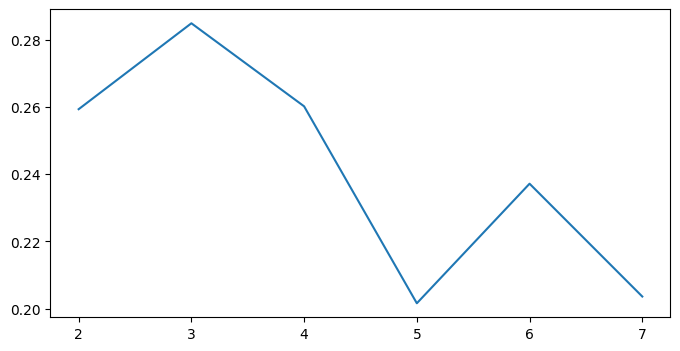

In [21]:
plt.figure(figsize=(8,4))

plt.plot(list(range(2, 8)), silhouette_scores)

plt.show()

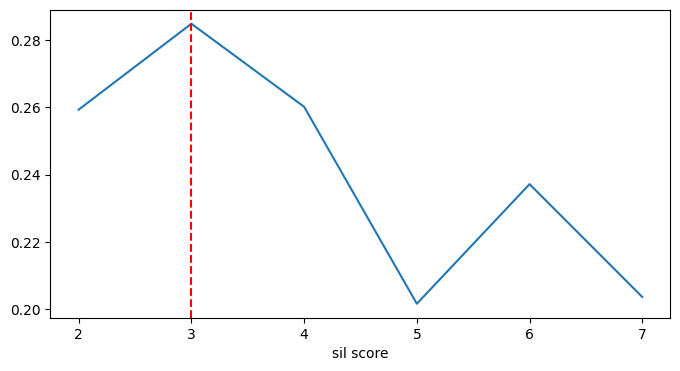

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(list(range(2,8)), silhouette_scores)
plt.axvline(best_k_wine, color='red', linestyle='--')

plt.xlabel("k")
plt.xlabel("sil score")

plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [2]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

X.shape

image shape: (533, 800, 3)


(426400, 3)

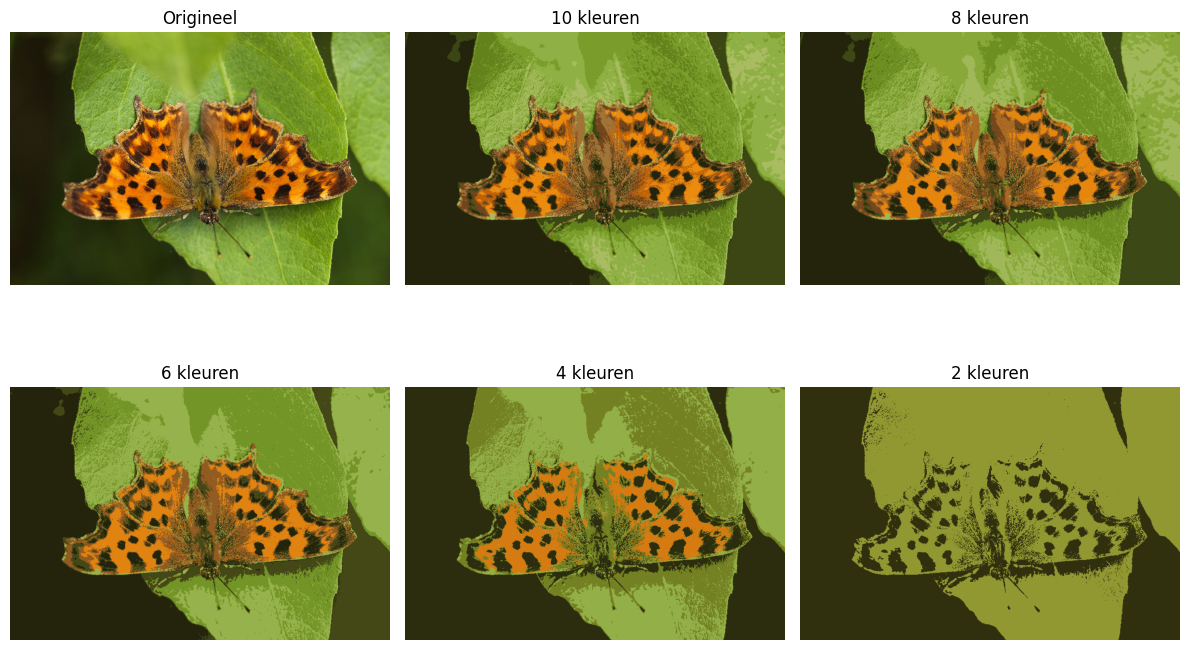

In [ ]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape.
# Bewaar het tuple n_colors = (10, 8, 6, 4, 2) en de 5 gesegmenteerde
# afbeeldingen in segmented_imgs (zelfde vorm als image).

n_colors = (10, 8, 6, 4, 2)
segmented_Images = []
for k in n_colors:
    kmean = KMeans(k, random_state=42, n_init=10).fit(X)

    segmented_Image = kmean.cluster_centers_[kmean.labels_].reshape(image.shape)
    segmented_Images.append(segmented_Image)
    

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i in range(6):
    axes.ravel()[i].axis('off')

axes.ravel()[0].imshow(image)
axes.ravel()[0].set_title('Origineel')

for i, n_clusters in enumerate(n_colors):
    axes.ravel()[i+1].imshow(segmented_Images[i]/255)
    
    axes.ravel()[i + 1].set_title(f'{n_colors[i]} kleuren')

plt.tight_layout()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

0.5817500491982808


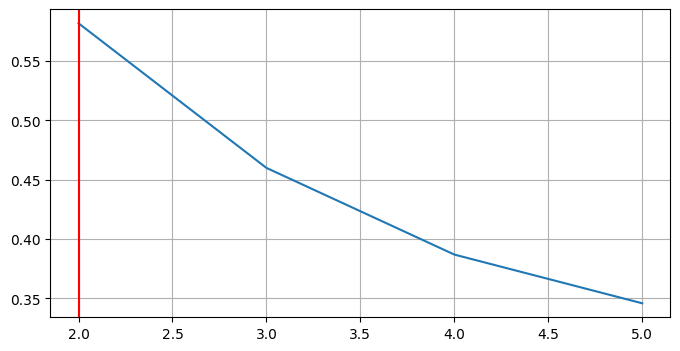

In [128]:
# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.

from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


iris = datasets.load_iris()
X = iris.data

#schaal data zodat alle feature gelijke gewicht krijgen 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



k_range_iris = list(range(2, 6))
sil_scores_iris = []
best_sil = -1.0
best_k_iris = 2

for k in k_range_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    
    sil = silhouette_score(X_scaled, kmeans.labels_)
    
    sil_scores_iris.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k_iris = k

silhouette_iris = best_sil


print(silhouette_iris)
silhouette_iris


plt.figure(figsize=(8,4))
plt.plot(k_range_iris, sil_scores_iris)

plt.axvline(best_k_iris, color="red")

plt.grid()


Scores: [-0.14729986910161358, -0.1941947686285083, 0.15971036873870176, 0.35651648142700726, 0.5080668523761808, 0.523400848673573]
best params: (0.7, 5)
best silhouette: 0.523400848673573


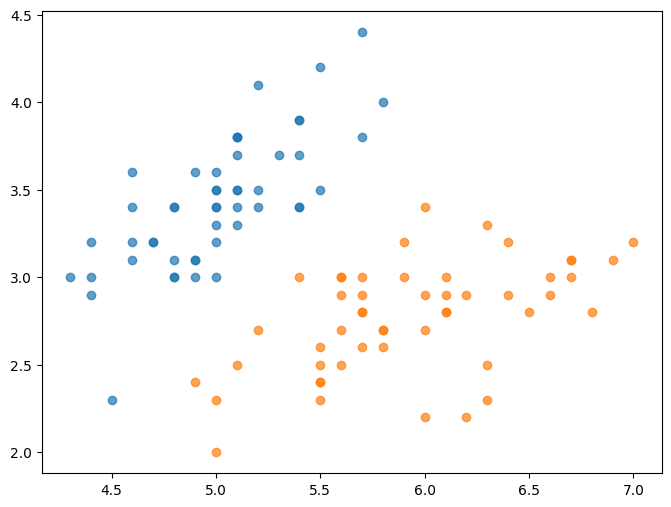

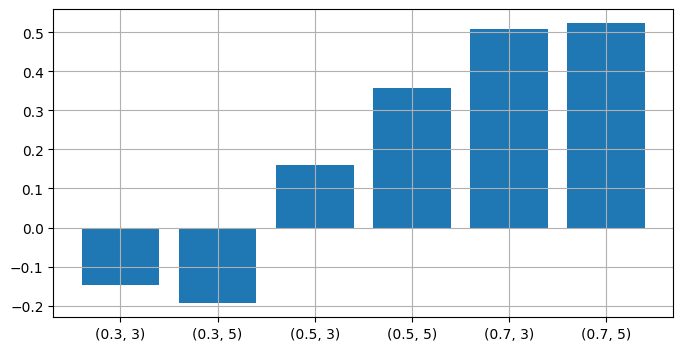

In [127]:
# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.


from sklearn import datasets
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


iris = datasets.load_iris()
X = iris.data
y = iris.target

#schaal data zodat alle feature gelijke gewicht krijgen 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



# Separate the two classes
class_0 = X[y == 0]
class_1 = X[y == 1]

# Create a scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(class_0[:, 0], class_0[:, 1], label='Class 0', alpha=0.7)
plt.scatter(class_1[:, 0], class_1[:, 1], label='Class 1', alpha=0.7)

dbscan_params = [
    (0.3, 3),
    (0.3, 5),
    (0.5, 3),
    (0.5, 5),
    (0.7, 3),
    (0.7, 5)
]
sil_scores_iris2 = []
best_sil = -1.0
best_params_iris = None

for eps, min_sample in dbscan_params:
    dbscan = DBSCAN(eps=eps, min_samples=min_sample).fit(X_scaled)
    labels = dbscan.labels_
    

    if len(set(labels)) >= 2:
        
        sil = silhouette_score(X_scaled, labels)
        
        sil_scores_iris2.append(sil)
        if sil > best_sil:
            best_sil = sil
            best_params_iris = (eps, min_sample)
        else:
            sil_scores_iris.append(None)

silhouette_iris = best_sil

print(f"Scores: {sil_scores_iris2}")
print(f"best params: {best_params_iris}")
print(f"best silhouette: {silhouette_iris}")



plt.figure(figsize=(8,4))

plt.bar([str(params) for params in dbscan_params], sil_scores_iris2)

plt.grid()




## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Best sil: 0.4390404164555763
Best k: 6


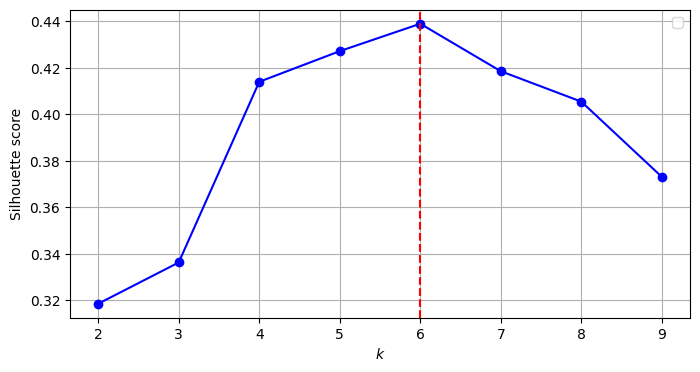

In [129]:
# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.

import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler 

customers = pd.read_csv("data/Mall_Customers.csv")


label_encoder = LabelEncoder()
customers['Gender'] = label_encoder.fit_transform(customers['Gender'])

X = customers.drop('Gender', axis=1)
y = customers['Gender']

scaler = StandardScaler()
customer_scaled = scaler.fit_transform(X)

#########################################################################
sil_scores_customer = []
best_sil_mall = -1
best_k_mall = 2 #wijst op aantal clusters

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(customer_scaled)
    sil = silhouette_score(customer_scaled, kmeans.labels_)
    
    sil_scores_customer.append(sil)
    
    if sil > best_sil_mall:
        best_sil_mall = sil
        
        best_k_mall = k
    
silhouette_mall = best_sil_mall    
    
print(f"Best sil: {silhouette_mall}")
print(f"Best k: {best_k_mall}")
    
    

# Silhouette per k
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), sil_scores_customer, 'bo-')
plt.axvline(best_k_mall, color='red', linestyle='--')

plt.xlabel('$k$')
plt.ylabel('Silhouette score')

plt.grid()
plt.legend()
plt.show()



No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Best sil: 0.21633674467685143
Best params: (0.7, 5)


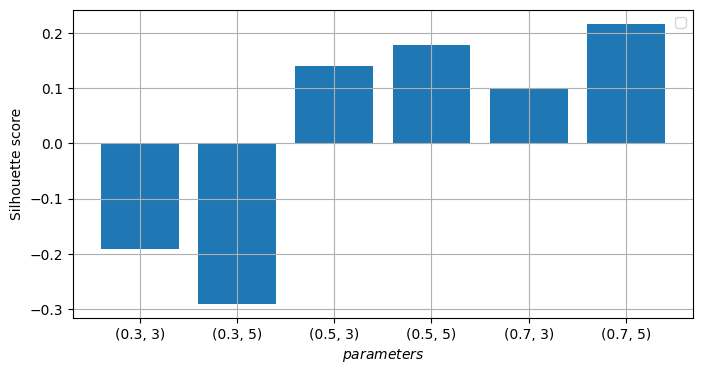

In [130]:
# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.

import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler 

customers = pd.read_csv("data/Mall_Customers.csv")


label_encoder = LabelEncoder()
customers['Gender'] = label_encoder.fit_transform(customers['Gender'])

X = customers.drop('Gender', axis=1)
y = customers['Gender']

scaler = StandardScaler()
customer_scaled = scaler.fit_transform(X)

#########################################################################
dbscan_params = [(0.3, 3), (0.3, 5),(0.5, 3), (0.5, 5), (0.7, 3), (0.7, 5)]
best_sil_mall = -1
best_params_mall = None
sil_scores_dbscan = []

for eps, samples in dbscan_params:
    dbscan = DBSCAN(eps=eps, min_samples=samples).fit(customer_scaled)
    
    labels = dbscan.labels_
  
    
    if len(set(labels)) >= 2:
        sil = silhouette_score(customer_scaled,labels)
        
        if sil > best_sil_mall:
            best_sil_mall = sil
            best_params_mall = (eps, samples)
        
        sil_scores_dbscan.append(sil)
        
    else:
        sil_scores_dbscan.append(None)

    
silhouette_mall = best_sil_mall    
    
print(f"Best sil: {silhouette_mall}")
print(f"Best params: {best_params_mall}")
    
    

# Silhouette per eps 
plt.figure(figsize=(8, 4))
plt.bar( [str(p) for p in dbscan_params], [0 if i is None else i for i in sil_scores_dbscan])

plt.xlabel('$parameters$')
plt.ylabel('Silhouette score')

plt.grid()
plt.legend()
plt.show()



## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [ ]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = ""

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = ""
